# Analysis of Customer Spending Patterns
This dataset analyses customer shopping behavior by examining demographic details, purchasing patterns, and preferences. It includes information on products bought, purchase frequency, spending amount, and promotional factors such as discounts and payment methods. The analysis helps understand customer choices and provides insight to support better business and marketing decisions.

Description of the variables of the data used here:


*  **Customer ID**: A unique identifier for each customer.
*   **Age**: The customer's age in years.
*   **Gender**: The customer's gender.
*   **Item Purchased**: The specific product that the customer bought.
*   **Category**: The type of product purchased.
*   **Purchase Amount (USD)**: The amount of money spent on the purchase in US dollars.
*   **Location**: The state or region in the U.S. where the customer is located.
*   **Size**: The size of the purchased item.
*   **Color**: The color of the item purchased.
*   **Season**: The season when the purchase was made.
*   **Review Rating**: The rating given by the customer for the product.
*   **Subscription Status**: Indicates whether the customer has an active subscription.
*   **Shipping Type**: The method used to ship the product.
*   **Discount Applied**: Indicates whether a discount was applied to the purchase.
*  **Promo Code Used**: Indicates whether a promotional code was used for the purchase.
*   **Previous Purchases**: The number of purchases the customer made before this transaction.
*   **Payment Method**: The method used to pay for the purchase.
*   **Frequency of Purchases**: How often the customer shops.





# Data Loading & Inspection


In [ ]:
# Imports the pandas and numpy libraries and renames them as pd and np
import pandas as pd
import numpy as np

#Loads the file
Shopping_Data = pd.read_csv('shopping_behavior.csv')

In [ ]:
#head() returns a specified number of rows
#Since no number is specified, it returns the first 5 rows by default
Shopping_Data.head()

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


In [ ]:
# shape describes the dimensions of an object (rows, columns)
Shopping_Data.shape

(3900, 18)

In [ ]:
# columns returns the column names of the DataFrame
Shopping_Data.columns

Index(['Customer ID', 'Age', 'Gender', 'Item Purchased', 'Category',
       'Purchase Amount (USD)', 'Location', 'Size', 'Color', 'Season',
       'Review Rating', 'Subscription Status', 'Shipping Type',
       'Discount Applied', 'Promo Code Used', 'Previous Purchases',
       'Payment Method', 'Frequency of Purchases'],
      dtype='object')

In [ ]:
# info() prints information about the dataset
# - column names, non-null counts, and data types
Shopping_Data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Customer ID             3900 non-null   int64  
 1   Age                     3900 non-null   int64  
 2   Gender                  3900 non-null   object 
 3   Item Purchased          3900 non-null   object 
 4   Category                3900 non-null   object 
 5   Purchase Amount (USD)   3900 non-null   int64  
 6   Location                3900 non-null   object 
 7   Size                    3900 non-null   object 
 8   Color                   3900 non-null   object 
 9   Season                  3900 non-null   object 
 10  Review Rating           3900 non-null   float64
 11  Subscription Status     3900 non-null   object 
 12  Shipping Type           3900 non-null   object 
 13  Discount Applied        3900 non-null   object 
 14  Promo Code Used         3900 non-null   

In [ ]:
#describe() returns a summary description of the data
Shopping_Data.describe()

,Customer ID,Age,Purchase Amount (USD),Review Rating,Previous Purchases
count,3900.000000,3900.000000,3900.000000,3900.000000,3900.000000
mean,1950.500000,44.068462,59.764359,3.749949,25.351538
std,1125.977353,15.207589,23.685392,0.716223,14.447125
min,1.000000,18.000000,20.000000,2.500000,1.000000
25%,975.750000,31.000000,39.000000,3.100000,13.000000
50%,1950.500000,44.000000,60.000000,3.700000,25.000000
75%,2925.250000,57.000000,81.000000,4.400000,38.000000
max,3900.000000,70.000000,100.000000,5.000000,50.000000


**Initial Observations:**

- The dataset contains **3,900 rows and 18 columns**. This is a moderate-sized dataset and does not require sampling.
- The majority of columns are of type `object` (categorical), which means they will require encoding before any numerical analysis or modeling.
- Numerical columns include: `Age`, `Purchase Amount (USD)`, `Review Rating`, and `Previous Purchases`.
- All numerical values appear to fall within realistic ranges: Age (18–70), Purchase Amount ($20–$100), Review Rating (2.5–5.0).
- `Customer ID` is numerical but is an identifier and carries no analytical value.


# Data Quality Assessment

In [ ]:
#Checking for missing values
# isnull() returns True for every cell that contains NaN
# sum() counts how many True values exist per column
Shopping_Data.isnull().sum()

,0
Customer ID,0
Age,0
Gender,0
Item Purchased,0
Category,0
Purchase Amount (USD),0
Location,0
Size,0
Color,0
Season,0


In [ ]:
#Checks for duplicate rows and counts how many are deplicates using sum
Shopping_Data.duplicated().sum()

np.int64(0)

In [ ]:
# Get all object columns with case inconsistencies in one line
# Identify object columns where case-insensitive unique counts are lower than actual unique counts
# (This flags columns where "Value" and "value" are being treated as different labels)
inconsistent = [col for col in Shopping_Data.select_dtypes(include=['object']).columns
                if Shopping_Data[col].str.lower().nunique() < Shopping_Data[col].nunique()]

print(f"Columns with inconsistent labels: {inconsistent}")

Columns with inconsistent labels: []


In [ ]:
#Checking for invalid values using min and max
# Get min and max for all columns to get for negative or impossible values
# loc used to access a group of rows and columns by label(s)
print(Shopping_Data.describe().loc[['min', 'max']])

     Customer ID   Age  Purchase Amount (USD)  Review Rating  \
min          1.0  18.0                   20.0            2.5   
max       3900.0  70.0                  100.0            5.0   

     Previous Purchases  
min                 1.0  
max                50.0  


**Data Quality Assessment Summary:**

| Issue | Method Used to Detect | Result |
|---|---|---|
| Missing values | isnull().sum() | None found |
| Duplicate rows | duplicated().sum() | None found |
| Inconsistent labels | Case-insensitive `nunique()` comparison | None found |
| Invalid values | describe().loc[['min','max']] | All values within valid ranges |
| Mixed/incorrect data types | info() already showed dtypes | No issues |

The dataset is clean with no quality issues detected across all five checks.

# Data Cleaning & Exploratory Data Analysis (EDA)

## Data Cleaning

As you saw in the data quality assessment, no issues were detected; however, one of the project requirements is to handle missing values. To demonstrate our ability to handle missing values, if they were present in our data, I will first sample the data, then create some missing values, and apply the steps to help resolve them.

In [ ]:
#Taking 20% of the organial dataset and then making sure they are reproducible
sample_data = Shopping_Data.sample(frac=0.2, random_state=42)
sample_data.head()

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
839,840,48,Male,Shirt,Clothing,31,Illinois,L,Teal,Spring,2.6,Yes,Free Shipping,Yes,Yes,10,Debit Card,Every 3 Months
1717,1718,29,Male,Hoodie,Clothing,50,Hawaii,L,Orange,Summer,2.9,No,Express,No,No,16,Debit Card,Bi-Weekly
321,322,41,Male,Sneakers,Footwear,36,Vermont,L,Orange,Summer,4.7,Yes,Free Shipping,Yes,Yes,48,Debit Card,Quarterly
3187,3188,67,Female,Blouse,Clothing,72,Texas,L,Indigo,Winter,3.2,No,Free Shipping,No,No,28,Debit Card,Weekly
2269,2270,49,Male,Skirt,Clothing,38,Kentucky,M,Yellow,Fall,4.4,No,Store Pickup,No,No,27,Credit Card,Annually


In [ ]:
#Finding out which columns are numerical cause that's what I'll be removing
sample_data.select_dtypes(include="number").columns

Index(['Customer ID', 'Age', 'Purchase Amount (USD)', 'Review Rating',
       'Previous Purchases'],
      dtype='object')

In [ ]:
#Randomly removing 10% of the selected columns to artificially make missing values.

np.random.seed(42)

for col in ['Purchase Amount (USD)', 'Review Rating',
       'Previous Purchases']:
    sample_data.loc[
        sample_data.sample(frac=0.1).index, col
    ] = np.nan

In [ ]:
# missing values after introduction
sample_data.isnull().sum()

,0
Customer ID,0
Age,0
Gender,0
Item Purchased,0
Category,0
Purchase Amount (USD),78
Location,0
Size,0
Color,0
Season,0


In [ ]:
#Figure out the total number of missing values
print("Total missing values:", sample_data.isnull().sum().sum())

Total missing values: 234


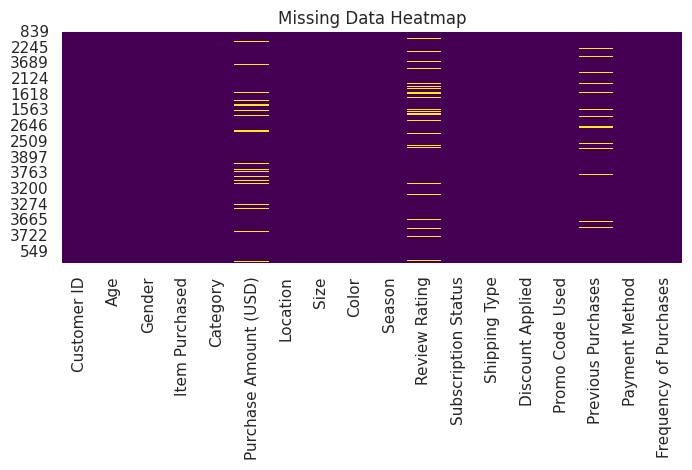

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

#Trying to visualize the missing data from our sample
# Yellow indicates missing, purple indicates present
plt.figure(figsize=(8, 3))
sns.heatmap(sample_data.isnull(), cbar=False, cmap='viridis')
plt.title('Missing Data Heatmap')
plt.show()

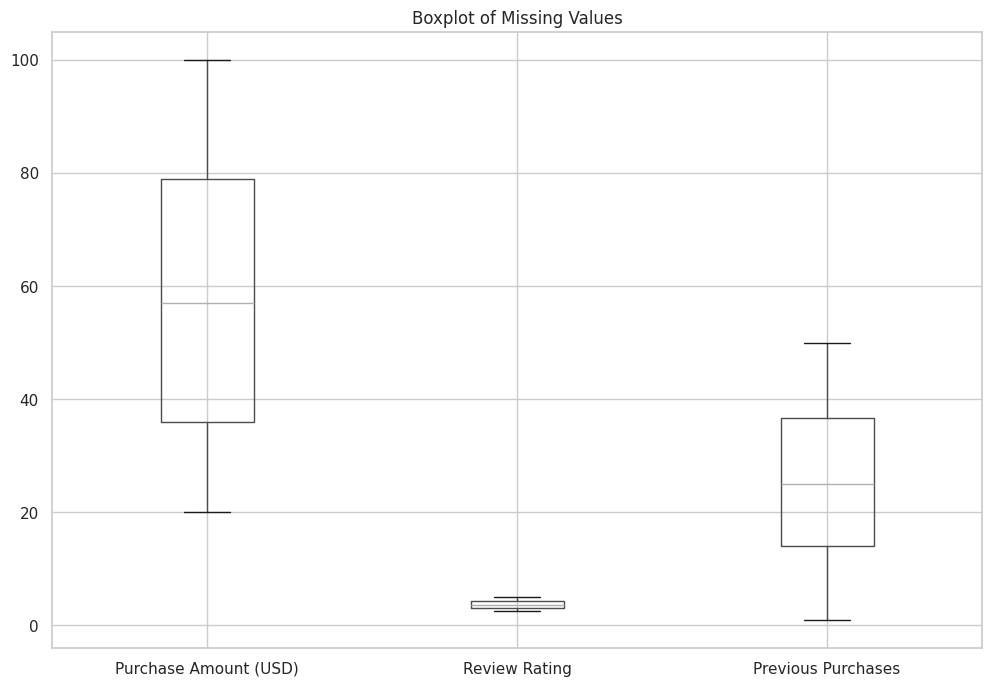

In [ ]:
# Visualising the distribution of columns with missing values using boxplots
# This helps determine whether the distribution is normal (suitable for mean imputation)
# or skewed (where median would be more appropriate)
sample_data[['Purchase Amount (USD)', 'Review Rating', 'Previous Purchases']].boxplot(figsize=(12,8))
plt.title('Boxplot of Missing Values')
plt.show()


### Method 1: Mean Imputation

**Why:** The boxplots show that all three columns have roughly symmetric, bell-shaped distributions with no significant outliers. When data is normally distributed, the mean is the best measure of central tendency, so replacing missing values with the mean introduces the least distortion to the data.

In [ ]:
# Method 1: Mean Imputation
# We create a copy so we can compare both methods side by side
sample_mean = sample_data.copy()
sample_mean = sample_mean.fillna({
    'Purchase Amount (USD)': sample_mean['Purchase Amount (USD)'].mean(),
    'Review Rating': sample_mean['Review Rating'].mean(),
    'Previous Purchases': sample_mean['Previous Purchases'].mean()
})

print("Missing values after mean imputation:")
print(sample_mean.isnull().sum())

Missing values after mean imputation:
Customer ID               0
Age                       0
Gender                    0
Item Purchased            0
Category                  0
Purchase Amount (USD)     0
Location                  0
Size                      0
Color                     0
Season                    0
Review Rating             0
Subscription Status       0
Shipping Type             0
Discount Applied          0
Promo Code Used           0
Previous Purchases        0
Payment Method            0
Frequency of Purchases    0
dtype: int64


### Method 2: Median Imputation

**Why:** The median is the middle value of sorted data and is not affected by extreme values the way the mean is. If the distribution were skewed or contained outliers, median imputation would be a safer choice because it would not be pulled in the direction of the extreme values. We apply it here for comparison.

In [ ]:
# Method 2: Median Imputation
sample_median = sample_data.copy()

sample_median = sample_median.fillna({
    'Purchase Amount (USD)': sample_median['Purchase Amount (USD)'].median(),
    'Review Rating':         sample_median['Review Rating'].median(),
    'Previous Purchases':    sample_median['Previous Purchases'].median()
})

print("Missing values after median imputation:")
print(sample_median.isnull().sum())

Missing values after median imputation:
Customer ID               0
Age                       0
Gender                    0
Item Purchased            0
Category                  0
Purchase Amount (USD)     0
Location                  0
Size                      0
Color                     0
Season                    0
Review Rating             0
Subscription Status       0
Shipping Type             0
Discount Applied          0
Promo Code Used           0
Previous Purchases        0
Payment Method            0
Frequency of Purchases    0
dtype: int64


In [ ]:
# Comparing the two methods by looking at the resulting means
comparison = pd.DataFrame({
    'Original Mean':       sample_data[['Purchase Amount (USD)', 'Review Rating', 'Previous Purchases']].mean(),
    'After Mean Impute':   sample_mean[['Purchase Amount (USD)', 'Review Rating', 'Previous Purchases']].mean(),
    'After Median Impute': sample_median[['Purchase Amount (USD)', 'Review Rating', 'Previous Purchases']].mean()
})
print(comparison)

                       Original Mean  After Mean Impute  After Median Impute
Purchase Amount (USD)      57.927350          57.927350            57.834615
Review Rating               3.739744           3.739744             3.735769
Previous Purchases         24.867521          24.867521            24.880769


**Comparison & Final Choice:**

As shown in the table above, both methods produce nearly identical results because the distributions are symmetric. The difference between mean and median is negligible, confirming that the data is not skewed.

**We choose mean imputation** as our final method because the data is normally distributed (as confirmed by the boxplots), making the mean the most representative central value. We proceed using `sample_mean` for any further work on the sample.

Now there are no missing values in our sample data.

## Exploratory Data Analysis (EDA)

To ensure the best results for EDA, first, we have to establish our goal. Before I explain our goal, I would like to note that we both had different goals, which you can see when you compare our labs, but we discussed and picked the goal that would be easier and provide more insights and use to our dataset. So, the labs might be different, but all work in the project has been collaborative.

Our goal is to determine which feature has the most revenue. Our target column will be Purchase Amount (USD). Our goal will be based on age, gender, category, season, etc, how much will the customer spend?

In [ ]:
# Quick statistical overview for our target feature
print(Shopping_Data['Purchase Amount (USD)'].describe())

count    3900.000000
mean       59.764359
std        23.685392
min        20.000000
25%        39.000000
50%        60.000000
75%        81.000000
max       100.000000
Name: Purchase Amount (USD), dtype: float64


In [ ]:
# Checking distribution of key categorical columns using value_counts()
# This helps detect class imbalance that could affect group-based analysis
print(Shopping_Data['Category'].value_counts())
print(Shopping_Data['Season'].value_counts())
print(Shopping_Data['Gender'].value_counts())

Category
Clothing       1737
Accessories    1240
Footwear        599
Outerwear       324
Name: count, dtype: int64
Season
Spring    999
Fall      975
Winter    971
Summer    955
Name: count, dtype: int64
Gender
Male      2652
Female    1248
Name: count, dtype: int64


In [ ]:
# Which category brings in the most total revenue?
category_revenue = Shopping_Data.groupby('Category')['Purchase Amount (USD)'].sum().sort_values(ascending=False)
print(category_revenue)

# Which season is most profitable for each gender?
pivot = Shopping_Data.pivot_table(index='Season', columns='Gender', values='Purchase Amount (USD)', aggfunc='sum')
print(pivot)


Category
Clothing       104264
Accessories     74200
Footwear        36093
Outerwear       18524
Name: Purchase Amount (USD), dtype: int64
Gender  Female   Male
Season               
Fall     20193  39825
Spring   18578  40101
Summer   18060  37717
Winter   18360  40247


In [ ]:
# Check if the average spend actually changes when a discount is applied
discount_impact = Shopping_Data.groupby('Discount Applied')['Purchase Amount (USD)'].mean()
print(discount_impact)

Discount Applied
No     60.130454
Yes    59.279070
Name: Purchase Amount (USD), dtype: float64


In [ ]:
# Check if the average spend actually changes when subscription is applied
sub_impact = Shopping_Data.groupby('Subscription Status')['Purchase Amount (USD)'].mean()
print("Average Spend by Subscription Status:")
print(sub_impact)

Average Spend by Subscription Status:
Subscription Status
No     59.865121
Yes    59.491928
Name: Purchase Amount (USD), dtype: float64


In [ ]:
# Check if the average spend actually changes with frequency of purchases
freq_impact = Shopping_Data.groupby('Frequency of Purchases')['Purchase Amount (USD)'].mean().sort_values(ascending=False)
print("\nAverage Spend by Purchase Frequency:")
print(freq_impact)


Average Spend by Purchase Frequency:
Frequency of Purchases
Bi-Weekly         60.694698
Annually          60.173077
Every 3 Months    60.082192
Quarterly         59.984014
Monthly           59.330922
Fortnightly       59.053506
Weekly            58.972171
Name: Purchase Amount (USD), dtype: float64


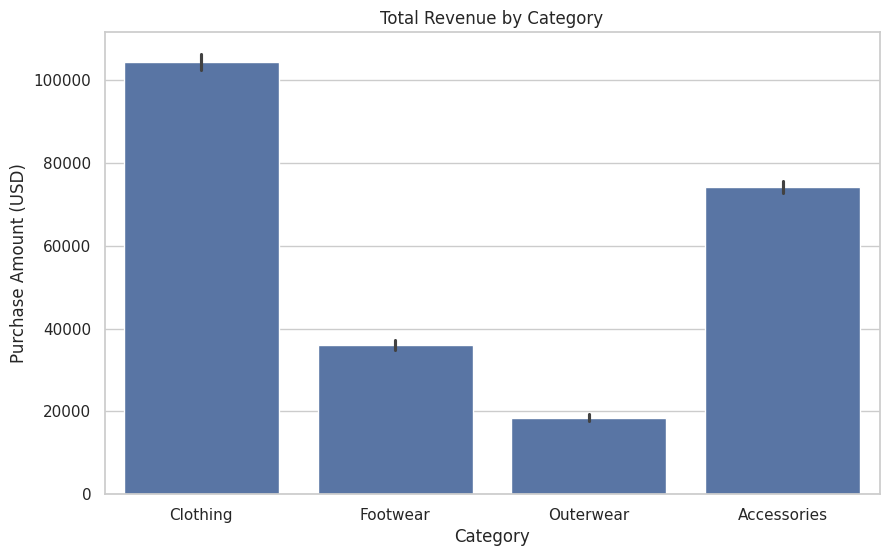

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

#Barplot
plt.figure(figsize=(10,6))
sns.barplot(x='Category', y='Purchase Amount (USD)', data=Shopping_Data, estimator=sum)
plt.title('Total Revenue by Category')
plt.show()

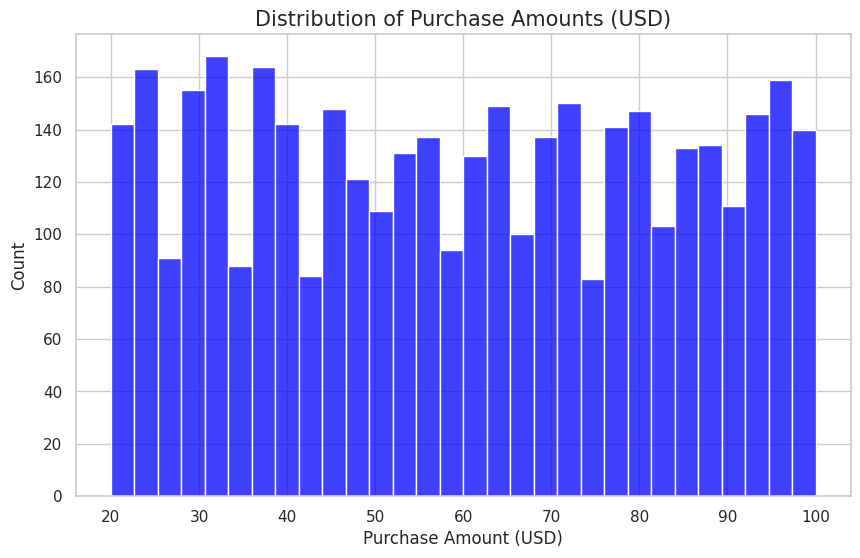

In [ ]:
# Histogram
# Set the style for a professional look
sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 6))

# Create the histogram
# bins=30 helps show detail without being too cluttered
sns.histplot(Shopping_Data['Purchase Amount (USD)'], bins=30, color='blue')

plt.title('Distribution of Purchase Amounts (USD)', fontsize=15)
plt.xlabel('Purchase Amount (USD)')

plt.show()

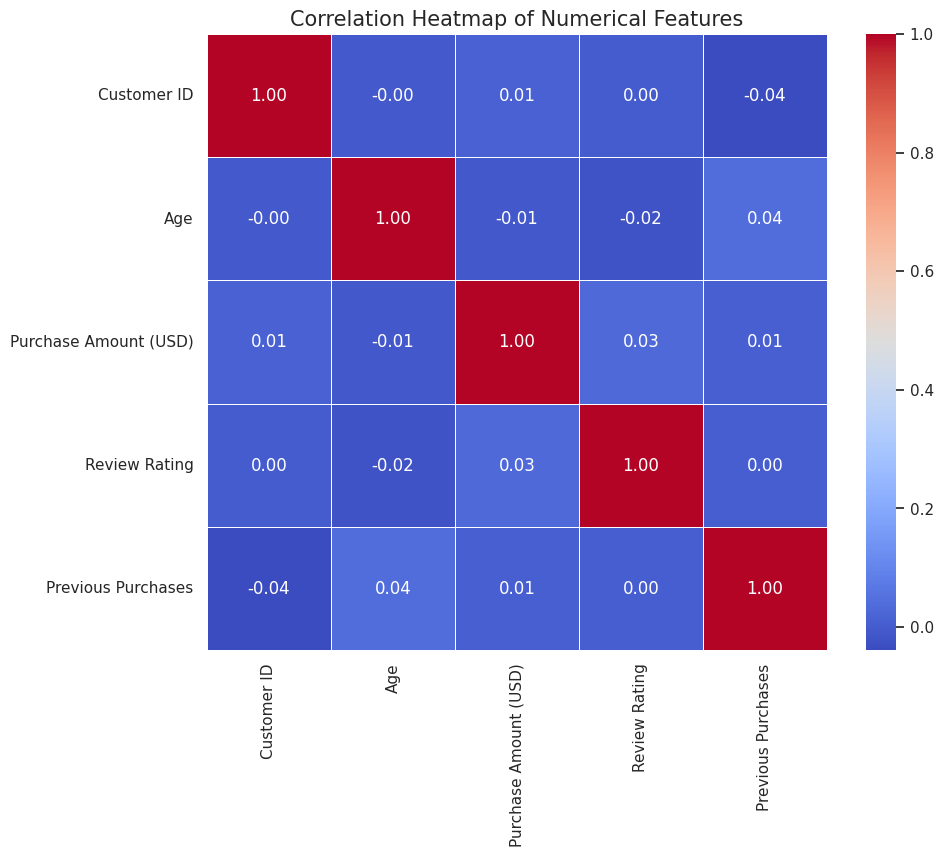

In [ ]:
# Correlation Heatmap
# 1. Select only numerical columns
numerical_data = Shopping_Data.select_dtypes(include=['int64', 'float64'])

# 2. Calculate the correlation matrix
corr_matrix = numerical_data.corr()

# 3. Create the heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)

plt.title('Correlation Heatmap of Numerical Features', fontsize=15)
plt.show()

Insights gained:


*  **Which category brings in the most total revenue?** <br>
Clothing generates the most revenue, $104,264. This is significantly higher than any other category. Why? If you look back at the value_counts(), you can see that clothing has the highest entries, indicating that the revenue is higher because of the frequency of purchases of clothing rather than because it is more expensive.
* **Which season is most profitable for each gender?** <br> Fall for females and winter for males. Another interesting observation is that across every season, male customers spend around double what female customers spend. Also, each gender has a stable range of spending across seasons, 37K - 40k for males and 18k - 20k for females.
*  **Do discounts, subscriptions, or frequency affect spending?** No. Average spend is virtually identical whether or not a discount was applied (60.13 vs 59.28), whether the customer has a subcription (59.87 vs 59.49), and across all frequency categories (58 - 60). This strongly suggests these features are not predictors of spending amount.





**Barplot:** <br> We visually inspected the relationship between category and purchase amount to compare all categories. The height of each bar represents total USD, clearly highlighting the gap between "Clothing" and other categories.

**Histogram:** <br> The distribution appears roughly uniform, indicating there is no particular spending amount that customers favor. In other words, no single price point stands out as the most popular.

**Heatmap:** <br> Since the data has not been encoded yet, the heatmap only reflects numerical features. It shows no strong correlation between any numeric variable and our target variable (purchase amount). This suggests that age is not a strong predictor, nor are other numeric features, implying that categorical features are likely more influential.


# Outliers Detection and Handling

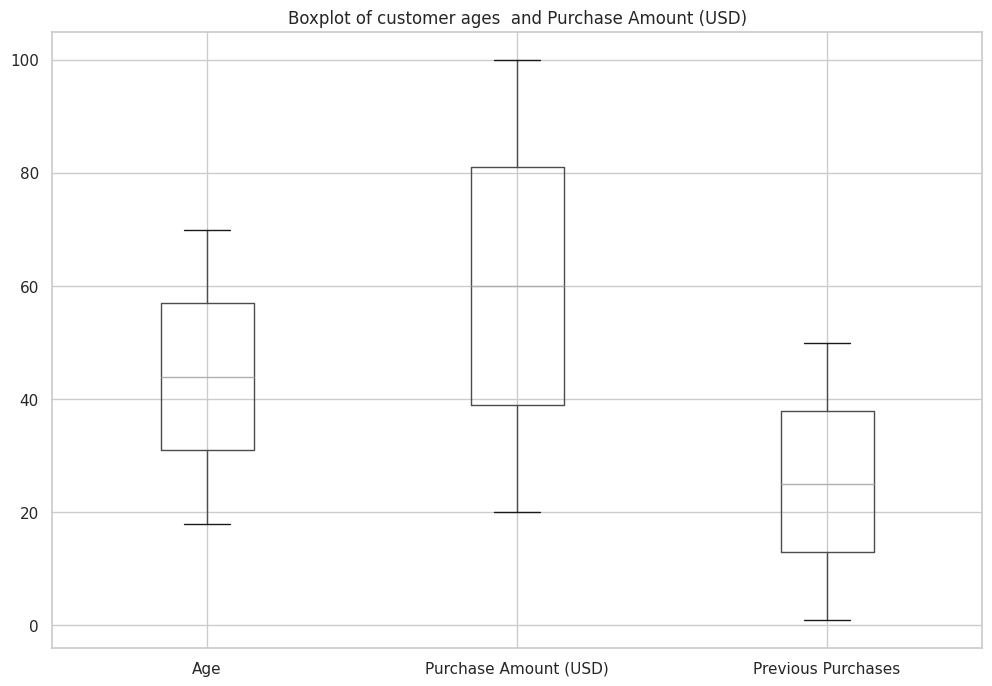

In [ ]:
# Method 1: Boxplots: visual detection of outliers
# Our goal is to detect outliers. First, we are going to check nurmerical columns using a boxplot.
# Points that appear beyond the whiskers of the boxplot are potential outliers
Shopping_Data[['Age', 'Purchase Amount (USD)', 'Previous Purchases']].boxplot(figsize=(12,8))
plt.title('Boxplot of customer ages  and Purchase Amount (USD)')
plt.show()

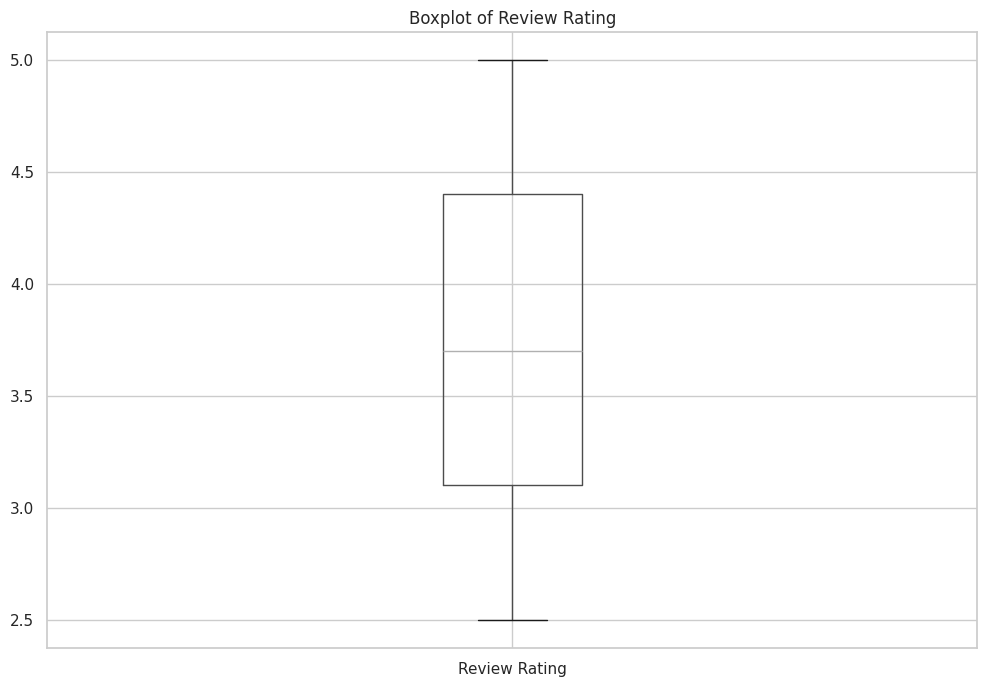

In [ ]:
# Checking the 'Review Rating' column separately as its range of number is different compared to other numeric columns
Shopping_Data[['Review Rating']].boxplot(figsize=(12,8))
plt.title('Boxplot of Review Rating')
plt.show()

In [ ]:
# Method 2: IQR Rule: statistical detection of outliers
# Checking using the IQR rule
# A value is considered an outlier if it falls below Q1 - 1.5*IQR or above Q3 + 1.5*IQR
# Instead of writing a code for each column to check the IQR, I'll be using a for loop instead for efficiency.

# Getting all numeric columns in the dataset
numeric_columns = Shopping_Data.select_dtypes(include=[np.number]).columns

# A for loop to check the IQR for each column
for col in numeric_columns:
    Q1 = Shopping_Data[col].quantile(0.25)
    Q3 = Shopping_Data[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    #Comparing each column after founding the lower and upper bound using sum() to showcase the overall number of outliers
    #Printing each column results
    Shopping_Data_outlier = ((Shopping_Data[col] < lower) | (Shopping_Data[col] > upper)).sum()
    print(f"{col}: Outliers using IQR method:")
    print(Shopping_Data_outlier)

Customer ID: Outliers using IQR method:
0
Age: Outliers using IQR method:
0
Purchase Amount (USD): Outliers using IQR method:
0
Review Rating: Outliers using IQR method:
0
Previous Purchases: Outliers using IQR method:
0


In [ ]:
# Method 3: describe(): cross-checking with summary statistics
# Checking each value manually using describe
Shopping_Data.describe()

,Customer ID,Age,Purchase Amount (USD),Review Rating,Previous Purchases
count,3900.000000,3900.000000,3900.000000,3900.000000,3900.000000
mean,1950.500000,44.068462,59.764359,3.749949,25.351538
std,1125.977353,15.207589,23.685392,0.716223,14.447125
min,1.000000,18.000000,20.000000,2.500000,1.000000
25%,975.750000,31.000000,39.000000,3.100000,13.000000
50%,1950.500000,44.000000,60.000000,3.700000,25.000000
75%,2925.250000,57.000000,81.000000,4.400000,38.000000
max,3900.000000,70.000000,100.000000,5.000000,50.000000


As shown, we inspected the data for outliers using three different methods, all of which indicated that there are no significant outliers. The summary statistics (describe) also confirms that all values fall within a reasonable range.

But let's say our data did have outliers compared to handling missing values, I won't be showcasing any of the work, but more so, writing it. If our data had any outliers for each numeric feature, here's how we would deal with them:


*  **Age:** Remove clearly unrealistic values such as (2 years old or 200 years old), as we have no reliable way to verify them. If outliers are numerous, using the median or mode would be a more efficient approach than simply dropping data.
*   **Review Rating:** Since this feature is on a fixed scale (1–5), outliers are unlikely. Any value outside this range would most likely be a data entry error and should be removed.
*   **Previous Purchases:** High values (e.g., 100) could be valid, as some customers may frequently purchase or have the financial means to do so. In this case, applying a log transformation would be appropriate, as it shrinks big numbers and stretches small numbers so the data becomes more balanced.
*  **Purchase amount:** High but realistic values like ($500) should be kept. However, capping should be used to limit the extreme values to predefined upper and lower bounds, ensuring no value exceeds these limits. But if it is an impossible value, removing it would be best.

It is also important to note that none of the numerical features show a strong correlation with the target variable. Therefore, prioritizing categorical features may be more effective. Outlier handling should be most carefully considered and prioritized for the target variable if needed.


# Data Transformation

In [ ]:
#Data before any normaliztion and encoding for comparing
Shopping_Data.head()

,Customer ID,Age,Gender,Item Purchased,Category,Purchase Amount (USD),Location,Size,Color,Season,Review Rating,Subscription Status,Shipping Type,Discount Applied,Promo Code Used,Previous Purchases,Payment Method,Frequency of Purchases
0,1,55,Male,Blouse,Clothing,53,Kentucky,L,Gray,Winter,3.1,Yes,Express,Yes,Yes,14,Venmo,Fortnightly
1,2,19,Male,Sweater,Clothing,64,Maine,L,Maroon,Winter,3.1,Yes,Express,Yes,Yes,2,Cash,Fortnightly
2,3,50,Male,Jeans,Clothing,73,Massachusetts,S,Maroon,Spring,3.1,Yes,Free Shipping,Yes,Yes,23,Credit Card,Weekly
3,4,21,Male,Sandals,Footwear,90,Rhode Island,M,Maroon,Spring,3.5,Yes,Next Day Air,Yes,Yes,49,PayPal,Weekly
4,5,45,Male,Blouse,Clothing,49,Oregon,M,Turquoise,Spring,2.7,Yes,Free Shipping,Yes,Yes,31,PayPal,Annually


**Feature Selection before Transformation:**

Removing irrelevant columns ensures efficiency and memory, as well as preventing 'noise'. Encoding values like customer ID or location when not relevant to our goal will create thousands of useless columns, which will slow down the computer and make the data harder to manage.

Justification for why these specific columns were removed:

- `Customer ID` — unique identifier, carries no analytical meaning
- `Item Purchased`, `Color`, `Size`, `Location` — too granular; no demonstrated relationship to purchase amount
- `Review Rating`, `Previous Purchases` — shown in EDA to have near-zero correlation with purchase amount
- `Subscription Status`, `Discount Applied`, `Promo Code Used`, `Shipping Type`, `Payment Method`, `Frequency of Purchases` — EDA confirmed these have negligible effect on average spending


In [ ]:
# List the exact names of the features to remove
columns_to_drop = [
    'Review Rating','Previous Purchases','Customer ID',
    'Item Purchased','Location','Size','Color',
    'Subscription Status','Shipping Type','Discount Applied',
    'Promo Code Used','Payment Method','Frequency of Purchases'
]

# Drop them in one go
# errors='ignore' ensures the code doesn't crash if a column was already removed
Shopping_Data = Shopping_Data.drop(columns=columns_to_drop, errors='ignore')

# Check what is left
print("Columns remaining:", Shopping_Data.columns.tolist())
Shopping_Data.head()


Columns remaining: ['Age', 'Gender', 'Category', 'Purchase Amount (USD)', 'Season']


,Age,Gender,Category,Purchase Amount (USD),Season
0,55,Male,Clothing,53,Winter
1,19,Male,Clothing,64,Winter
2,50,Male,Clothing,73,Spring
3,21,Male,Footwear,90,Spring
4,45,Male,Clothing,49,Spring


### Feature Scaling MinMax Normaliztion
*   **Why is scaling necessary?** <br> To prevent features with larger magnitudes from dominating smaller-scale features during model training, it's best to scale them so they all have equal "Importance".

*   **Why MinMax Scaling?** <br> MinMax was selected because it rescales numerical features into a range [0,1], which matches the range of our one-hot encoded categorical columns (also 0 or 1).This ensures all features, both numeric and encoded, share the same scale and are treated with equal importance.




In [ ]:
from sklearn.preprocessing import MinMaxScaler
numeric_columns = Shopping_Data.select_dtypes(include=['number']).columns

#Excluding our target value
numeric_columns = numeric_columns.drop('Purchase Amount (USD)')

scaler = MinMaxScaler()
Shopping_Data[numeric_columns] = scaler.fit_transform(Shopping_Data[numeric_columns])

#Confirming that all values have effectively been scaled
Shopping_Data[numeric_columns].head()

,Age
0,0.711538
1,0.019231
2,0.615385
3,0.057692
4,0.519231


### Categorical Encoding One Hot Encoding
*   **Why is encoding required?** <br> Encoding leads to a better model, and most algorithms cannot handle the categorical variables unless they are converted into numerical values. So encoding ensures the computer can understand the data.

*   **Why One Hot Encoding?** <br> Our Categorical Columns have no natural order, so using label encoding would cause the model to incorrectly interpret these numbers as having magnitude. One-Hot Encoding creates a separate binary column for each category, preserving the nominal nature of these variables.




In [ ]:
import pandas as pd
categorical_columns = Shopping_Data.select_dtypes(include=['object']).columns

#One-hot encoding the categorical data
Shopping_Data = pd.get_dummies(Shopping_Data, columns=categorical_columns)

#Showcase the final result
Shopping_Data.head()

,Age,Purchase Amount (USD),Gender_Female,Gender_Male,Category_Accessories,Category_Clothing,Category_Footwear,Category_Outerwear,Season_Fall,Season_Spring,Season_Summer,Season_Winter
0,0.711538,53,False,True,False,True,False,False,False,False,False,True
1,0.019231,64,False,True,False,True,False,False,False,False,False,True
2,0.615385,73,False,True,False,True,False,False,False,True,False,False
3,0.057692,90,False,True,False,False,True,False,False,True,False,False
4,0.519231,49,False,True,False,True,False,False,False,True,False,False


# Feature Engineering

<font size = "5">**New Feature: Age Group**</font>

*   **Why was the feature created?** <br> Analysing spending by individual age is noisy; it is often difficult to see a clear trend because spending can vary randomly from year to year. By "binning" the ages into broader categories, we can see different consumer behaviors at different life stages.
*   **How does it improve the analysis?**<br>
Instead of 53 unique age values, we now have 4 meaningful groups that can be compared directly. This reduces noise and makes group comparisons much more interpretable. The model could tell us, for instance, that  "Seniors spend significantly more on Outerwear than Young Adults." These generalized patterns are more useful to a business.



In [ ]:
# Create Age Groups
bins = [0, 19, 35, 55, 100]
labels = ['Teen', 'Young Adult', 'Adult', 'Senior']
Shopping_Data['Age Group'] = pd.cut(Shopping_Data['Age'], bins=bins, labels=labels)
Shopping_Data.head()

,Age,Purchase Amount (USD),Gender_Female,Gender_Male,Category_Accessories,Category_Clothing,Category_Footwear,Category_Outerwear,Season_Fall,Season_Spring,Season_Summer,Season_Winter,Age Group
0,0.711538,53,False,True,False,True,False,False,False,False,False,True,Teen
1,0.019231,64,False,True,False,True,False,False,False,False,False,True,Teen
2,0.615385,73,False,True,False,True,False,False,False,True,False,False,Teen
3,0.057692,90,False,True,False,False,True,False,False,True,False,False,Teen
4,0.519231,49,False,True,False,True,False,False,False,True,False,False,Teen


In [ ]:
# One-hot encoding  the new categorical feature
Shopping_Data = pd.get_dummies(Shopping_Data, columns=['Age Group'])

#Showcase the final result
Shopping_Data.head()

,Age,Purchase Amount (USD),Gender_Female,Gender_Male,Category_Accessories,Category_Clothing,Category_Footwear,Category_Outerwear,Season_Fall,Season_Spring,Season_Summer,Season_Winter,Age Group_Teen,Age Group_Young Adult,Age Group_Adult,Age Group_Senior
0,0.711538,53,False,True,False,True,False,False,False,False,False,True,True,False,False,False
1,0.019231,64,False,True,False,True,False,False,False,False,False,True,True,False,False,False
2,0.615385,73,False,True,False,True,False,False,False,True,False,False,True,False,False,False
3,0.057692,90,False,True,False,False,True,False,False,True,False,False,True,False,False,False
4,0.519231,49,False,True,False,True,False,False,False,True,False,False,True,False,False,False


## Feature Selection

*   **Why feature Selection is useful?** <br> after one-hot encoding, our dataset has many columns. Not all of them are equally useful for predicting Purchase Amount. Selecting only the most relevant features reduces overfitting, speeds up computation, and makes the model easier to interpret.



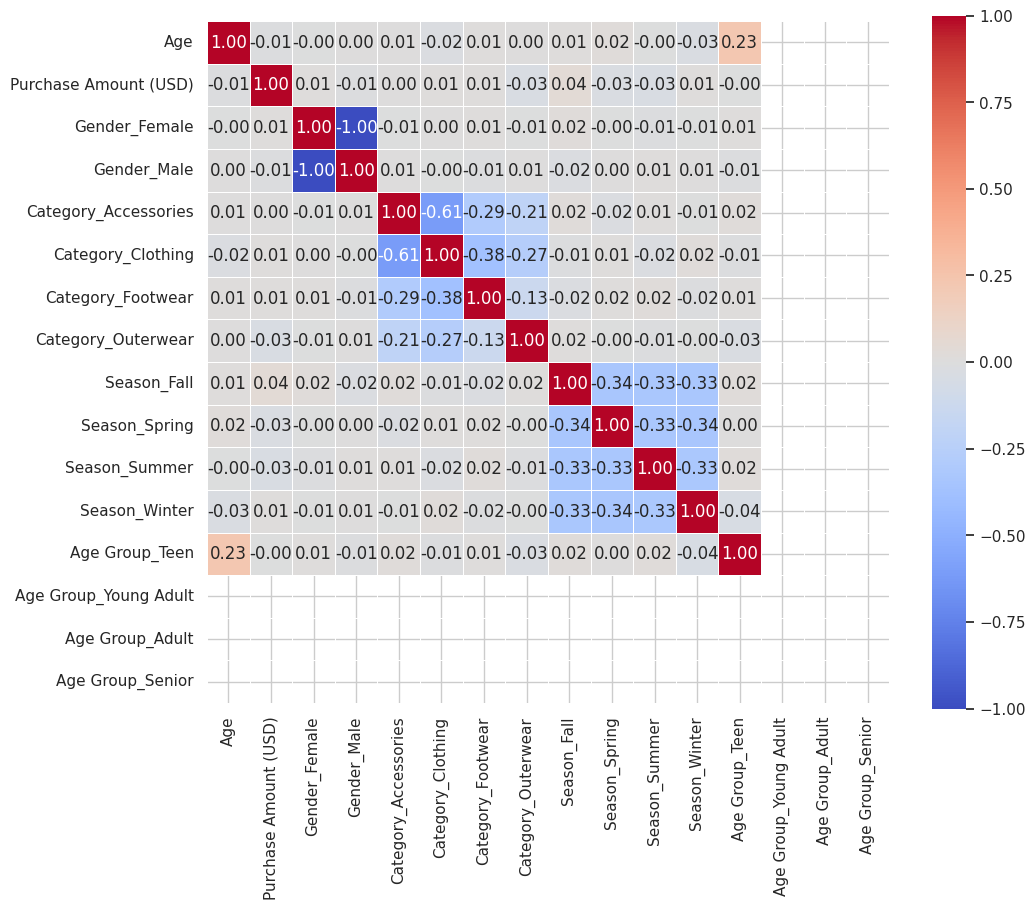

Top features by correlation with Purchase Amount:
Season_Fall           0.043701
Category_Outerwear    0.032938
Season_Summer         0.032681
Season_Spring         0.025439
Name: Purchase Amount (USD), dtype: float64


In [ ]:
# Method 1: Correlation Matrix
# Features most correlated with Purchase Amount (USD) are the strongest candidates
# Calculate the correlation matrix for the DataFrame
corr = Shopping_Data.corr()

# Set the figure size for the heatmap to ensure readability
plt.figure(figsize=(11, 9))

# Create a heatmap of the correlation matrix
# annot=True displays the correlation coefficients on the heatmap cells
# fmt = ".2f" shows 2 digits after the decimal
sns.heatmap(corr, annot=True, cmap='coolwarm', square=True, linewidths=.5,  fmt=".2f")

# Display the plot
plt.show()

# Top features by absolute correlation with target
target_corr = corr['Purchase Amount (USD)'].drop('Purchase Amount (USD)').abs().sort_values(ascending=False)
print("Top features by correlation with Purchase Amount:")
print(target_corr.head(4))

### Insights from Correlation Matrix:

*  The heatmap shows the relationship between all encoded features and the target variable. Features with higher absolute correlation values are stronger linear predictors of Purchase Amount. The top features identified include Season and Category encoded columns, confirming our EDA finding that categorical variables drive spending more than numerical ones.


In [ ]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LinearRegression

# Method 2: Recursive Feature Elimination (RFE)
# RFE iteratively removes the least important features based on model coefficients
# Define the feature set (X) by dropping the target variable and the target variable (y)
X = Shopping_Data.drop('Purchase Amount (USD)', axis=1)
y = Shopping_Data['Purchase Amount (USD)']

# Initialize a Linear Regression model as the estimator for RFE
model = LinearRegression()

# Initialize RFE with the model and specify to select 4 features
rfe = RFE(model, n_features_to_select=4)

# Fit RFE to the data and transform X to get the selected features
X_selected = rfe.fit_transform(X, y)

# Print a boolean mask indicating which features were selected (True for selected, False for not selected)
print(rfe.support_)


[False False False False False False  True  True  True  True False False
 False False False]


In [ ]:
# Get the names of the selected features
Selected_features = X.columns[rfe.support_]

# Print the names of the features selected by RFE
print(Selected_features)

Index(['Category_Outerwear', 'Season_Fall', 'Season_Spring', 'Season_Summer'], dtype='object')


### Insights from RFE:

*   **Selected Features**: The RFE process selected Category_Outerwear, Season_Fall, Season_Spring, and Season_Summer as the most prominent features for predicting Purchase Amount (USD) based on the linear regression model. These align with the patterns discovered in EDA that these categories and seasons have a significant impact on purchase amounts.

## Feature Extraction


*   **Why PCA is applied ?**<br>
After one-hot encoding, our dataset has many columns.PCA is a technique used to reduce the dimensionality of a dataset by creating new features that summarize the data. This section applies PCA to extract the most important features from the dataset into a smaller number of components.


In [ ]:
from sklearn.decomposition import PCA
import numpy as np

# Apply PCA with 2 components to the full encoded dataset
pca = PCA(n_components=2)

# Fit PCA to the DataFrame and transform the data
# This creates a new array (X_pca) with the specified number of components
X_pca = pca.fit_transform(Shopping_Data)

# Print the explained variance ratio for each principal component
# This indicates the proportion of the dataset's variance that lies along each principal component
print("Explained Variance Ratio of Principal Components:")
print(pca.explained_variance_ratio_)

Explained Variance Ratio of Principal Components:
[9.96522570e-01 7.73604476e-04]


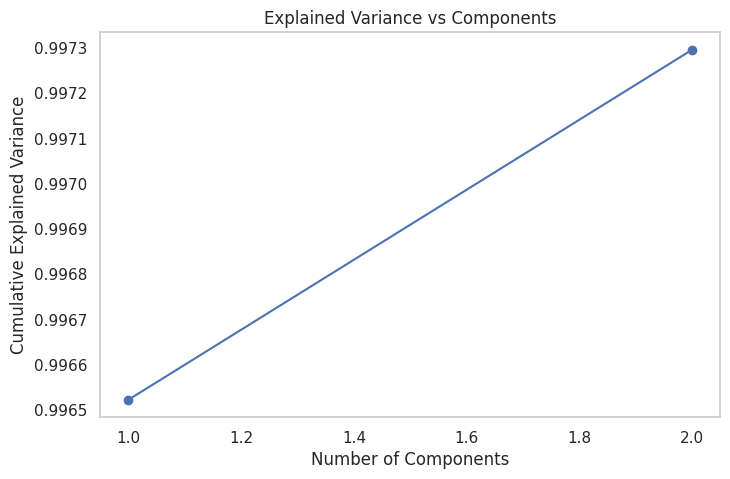

In [ ]:
import matplotlib.pyplot as plt
# Plotting cumulative explained variance to visualise how many components are needed

# Calculate the cumulative explained variance from the explained variance ratio of PCA components
cumulative_variance = np.cumsum(pca.explained_variance_ratio_)

# Set the figure size for the plot
plt.figure(figsize=(8,5))

# Plot the cumulative explained variance
# 'marker='o'' adds circular markers to each data point
plt.plot(range(1, len(cumulative_variance)+1), cumulative_variance, marker='o')


plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.title('Explained Variance vs Components')

# Add a grid to the plot for better readability
plt.grid()

# Display the plot
plt.show()

**PCA Interpretation:**

For PCA1, it explains approximately 99.65% of the variance, while PCA2 explains only 0.077%, indicating that most of the information can be captured using a single component in the dataset.

This result tells us the dataset is essentially one-dimensional in its variance most features move together or are dominated by one underlying factor which would most likey be the purchase amount itself.


# Analysis & Results





## 1. Final Dataset Summary
**Final Dataset Summary:**

| Item | Before Processing | After Processing |
|---|---|---|
| Rows | 3,900 | 3,900 (no rows removed) |
| Columns | 18 | 16 (after encoding) |
| Missing values | 0 | 0 |
| Duplicates | 0 | 0 |
| Outliers removed | 0 | 0 |

**What changed after preprocessing:**
- 13 irrelevant columns were dropped based on EDA evidence that they do not affect Purchase Amount
- `Age` was scaled to [0,1] using MinMaxScaler
- All categorical columns (Gender, Category, Season) were one-hot encoded into binary columns
- A new `Age Group` feature was engineered and encoded
- No rows were removed; the dataset was already clean




## 2. Key Statistical Results
**=== TARGET VARIABLE: Purchase Amount (USD) ===** <br>
Has a range of 20 - 100 dollars and a mean of $59.76.

**=== TOTAL REVENUE BY CATEGORY ===** <br>
|Category| Revenue|
|---|---|
|Clothing |      104,264|
|Accessories |    74,200|
|Footwear    |    36,093|
|Outerwear   |    18,524|

Clothing generates nearly 1.4x more revenue than Accessories and 2.9x more than Footwear.


**=== AVERAGE SPEND BY GENDER ===** <br>
|Gender|Avg Spend|
|---|---|
|Female |   60.249199|
|Male   |   59.536199|

Despite the large difference in customer count, males and females spend almost the same amount per transaction.


**=== AVERAGE SPEND BY SEASON ===**
|Season| Avg Spend|
|---|---|
Fall    |  61.556923
Winter  |  60.357364
Spring  |  58.737738
Summer  |  58.405236

Average spend is nearly identical across all seasons, with less than a $3.15 difference between the highest (Fall) and lowest (Summer).


**=== MOST COMMON CATEGORY ===**
|Category| Freq|
|---|---|
Clothing    |   1737
Accessories  |  1240
Footwear     |   599
Outerwear     |  324

Clothing is the most frequently purchased category, appearing 1.4x more than Accessories and over 5x more than Outerwear.


**=== REVENUE BY SEASON AND GENDER ===**
|Gender | Female |  Male|
|---|---|---|
|Season |              
Fall   |  20193 | 39825
Spring  | 18578 |  40101
Summer |  18060 |  37717
Winter |  18360 | 40247

Male customers contribute roughly double the revenue of female customers in every season, and spending remains stable across all seasons for both genders.

## 3. Final Insights

<font size = "4"> **What is the main story in the data?** <br>

 In this dataset, the revenue is driven by how many people buy something, not how much they spend. In the statistical analysis, anaylsis shows that all categories have the same average prices, but clothing has more transactions than outerwear, which is why clothing dominates revenue; it's about volume, not price. We also know that Males generate double the revenue of females, but their average spend is almost identical. The gap is purely because there are 2x more male customers. Discounts, promo codes, and subscriptions also make no difference to how much someone spends per transaction. That also applies to seasons. So you can say that **the main story in the dataset is that no matter what you change in the features, the average customer still spends around $60. The only thing that changes total revenue is how many customers are buying.**
***
<font size = "4"> **What patterns and trends were discovered?**

1.   **Gender gap is large.** Male customers outnumber female customers 2:1 in this dataset, and their total spending follows the same ratio. Though, the *average* spend per transaction is nearly identical, meaning the gap is
driven entirely by the number of male customers, not by males spending more per visit.
2.   **Season has no on affect individual spending.** All four seasons produced nearly identical average purchase amounts. Businesses cannot expect to charge more, or that customers will spend more, during any particular season.
1.   **Promotions and subscriptions have no measurable impact on spending amount.** Discount applied, promo codes, and subscription status all produced average spending differences of less than $1. This suggests these programs are not driving customers to spend more per transaction.
2.   **Numeric features are weak predictors.** The correlation heatmap and RFE both confirmed that Age, Review Rating, and Previous Purchases have near-zero correlation with Purchase Amount. Spending behavior in this dataset is categorical in nature *what* you buy matters far more.
***
<font size = "4">**What is the most important conclusion supported by data?**

To grow revenue, the best strategy would be to increase the transaction volume in the clothing category and also try to reduce the gender imbalance in the customer base. What I mean by that is we already know that revenue is driven by the number of people who buy, not by the amount they spend, so the logical way to grow revenue is to get more people buying. And since Clothing already has the highest volume and highest revenue, focusing there gives the biggest return. And male customers have the highest revenue, but that's only because there are double the male customers, not because they spend more. So if the business could attract more female customers, revenue would grow proportionally since female customers spend just as much per transaction as male customers do.

